# Solution 3 (comparison only): iterative similarity + global assignment

> **Throwaway experiment.** The main method is greedy percolation (`solution.ipynb`). This notebook only tests another alternative and compares it with percolation and with solution 2. All outputs are in `solution3_out/`; delete that folder and this notebook to remove everything. Main deliverables (`config.json`, `results/`, `predictions/`, `report.md`) and `solution2_out/` are only **read**.

**Idea.** Solution 2 matched globally but only once, using the given seeds. Percolation iterates but matches greedily, one pair at a time. This method keeps both ideas: in every **round** it
1. computes the vote matrix from the current anchors (`M[u, v]` = matched neighbour pairs supporting `(u, v)`),
2. solves one global assignment (`scipy.optimize.linear_sum_assignment`) over the unmatched nodes,
3. **locks in only the confident pairs**: at least `tau` votes and a margin of at least `margin` votes over the runner-up in the pair's row and column; at most the best `frac` of them per round,
4. adds the locked pairs as new anchors and repeats until nothing is confident enough. An optional `finish` step assigns the remaining nodes once with at least `tau` votes.

It answers: does matching globally in rounds beat matching greedily one pair at a time?

## 1. Setup and data loading (same loader and metrics as the main notebook)

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from scipy.optimize import linear_sum_assignment

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
DATA = Path('student/seed_based')
MAIN = Path('results')            # main (percolation) results: read only
SOL2 = Path('solution2_out')      # solution 2 results: read only
OUT = Path('solution3_out')       # everything this notebook writes
OUT.mkdir(exist_ok=True)
(OUT / 'figs').mkdir(exist_ok=True)

In [2]:
def build_adj(edges, n):
    """Symmetric 0/1 CSR adjacency without self-loops or duplicate edges."""
    m = sp.coo_matrix((np.ones(len(edges)), (edges.source, edges.target)), shape=(n, n))
    m = (m + m.T).tocsr()
    m.setdiag(0)
    m.eliminate_zeros()
    m.data[:] = 1.0
    return m


def load_instance(split, name, seed_kind="random", seed_pct=5):
    d = DATA / split / name
    n_a = len(pd.read_csv(d / "nodes_a.csv"))
    n_b = len(pd.read_csv(d / "nodes_b.csv"))
    A = build_adj(pd.read_csv(d / "edges_a.csv"), n_a)
    B = build_adj(pd.read_csv(d / "edges_b.csv"), n_b)
    seeds = pd.read_csv(d / f"seeds_{seed_kind}_{seed_pct:02d}.csv")
    seeds = dict(zip(seeds.node_a, seeds.node_b))
    gt = d / "ground_truth.csv"
    truth = None
    if gt.exists():
        t = pd.read_csv(gt)
        truth = dict(zip(t.node_a, t.node_b))
    meta = json.loads((d / "metadata.json").read_text())
    return A, B, seeds, truth, meta


In [3]:
def evaluate(pred, truth, seeds, n):
    """Precision / recall / F1 / coverage, overall and on unseeded nodes only."""
    correct = sum(truth.get(a) == b for a, b in pred.items())
    p = correct / len(pred) if pred else 0.0
    r = correct / n
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    un_pred = {a: b for a, b in pred.items() if a not in seeds}
    un_truth_n = n - len(seeds)
    un_correct = sum(truth.get(a) == b for a, b in un_pred.items())
    un_p = un_correct / len(un_pred) if un_pred else 0.0
    un_r = un_correct / un_truth_n if un_truth_n else 0.0
    un_f1 = 2 * un_p * un_r / (un_p + un_r) if un_p + un_r else 0.0
    return dict(
        precision=p, recall=r, f1=f1, coverage=len(pred) / n,
        unseeded_precision=un_p, unseeded_recall=un_r, unseeded_f1=un_f1,
        unseeded_coverage=len(un_pred) / un_truth_n if un_truth_n else 0.0,
    )


def degree_rank_baseline(A, B, seeds):
    """Pair unseeded nodes by degree rank (a deliberately weak floor)."""
    da = np.asarray(A.sum(1)).ravel()
    db = np.asarray(B.sum(1)).ravel()
    ua = [u for u in np.argsort(-da, kind="stable") if u not in seeds]
    used_b = set(seeds.values())
    ub = [v for v in np.argsort(-db, kind="stable") if v not in used_b]
    pred = dict(seeds)
    pred.update(zip(ua, ub))
    return pred


## 2. The method
`match_iter` keeps the vote matrix `M` up to date incrementally (new anchors add votes through `A[:, new_a] @ B[:, new_b].T`). Each round solves a rectangular assignment on the unmatched nodes, measures every assigned pair's votes and margin over its row/column runner-up, and locks in the confident ones. A small degree-similarity term breaks ties. Every locked pair is logged with its round, votes and margin.

In [4]:
def match_iter(A, B, seeds, tau=1, margin=1, frac=1.0, finish=False, max_rounds=300):
    """Iterative similarity + global assignment: lock in confident pairs each round."""
    n = A.shape[0]
    Ac, Bc = A.tocsc(), B.tocsc()
    dA = np.asarray(A.sum(1)).ravel()
    dB = np.asarray(B.sum(1)).ravel()
    tb = (-np.abs(dA[:, None] - dB[None, :]) / (max(dA.max(), dB.max()) + 1) * 1e-3).astype(np.float32)
    P = sp.csr_matrix((np.ones(len(seeds)), (list(seeds.keys()), list(seeds.values()))), shape=(n, n))
    M = (A @ P @ B.T).toarray().astype(np.float32)
    used_a = np.zeros(n, bool); used_b = np.zeros(n, bool)
    for a, b in seeds.items():
        used_a[a] = used_b[b] = True
    pred, log = dict(seeds), []

    def assign():
        ua, ub = np.where(~used_a)[0], np.where(~used_b)[0]
        Su = M[np.ix_(ua, ub)]
        ri, ci = linear_sum_assignment(-(Su + tb[np.ix_(ua, ub)]))
        s = Su[ri, ci]
        if Su.shape[0] > 1 and Su.shape[1] > 1:   # runner-up in the pair's row and column
            p = np.partition(Su, -2, axis=1)[:, -2:]; rmax, rsec = p.max(1), p.min(1)
            p = np.partition(Su, -2, axis=0)[-2:, :]; cmax, csec = p.max(0), p.min(0)
            alt = np.maximum(np.where(s >= rmax[ri], rsec[ri], rmax[ri]), np.where(s >= cmax[ci], csec[ci], cmax[ci]))
        else:
            alt = np.zeros_like(s)
        return ua[ri], ub[ci], s, s - alt

    rnd = 0
    for rnd in range(1, max_rounds + 1):
        if used_a.all():
            break
        ra, cb, s, gap = assign()
        idx = np.where((s >= tau) & (gap >= margin))[0]
        if len(idx) == 0:
            break
        if frac < 1:
            idx = idx[np.lexsort((-s[idx], -gap[idx]))][: max(1, int(np.ceil(frac * len(idx))))]
        la, lb = ra[idx], cb[idx]
        for u, v, sc, g in zip(la, lb, s[idx], gap[idx]):
            pred[int(u)] = int(v); log.append((int(u), int(v), float(sc), float(g), rnd))
        used_a[la] = used_b[lb] = True
        M += (Ac[:, la] @ Bc[:, lb].T).toarray().astype(np.float32)
    if finish and not used_a.all():
        ra, cb, s, gap = assign()
        for u, v, sc, g in zip(ra, cb, s, gap):
            if sc >= tau:
                pred[int(u)] = int(v); log.append((int(u), int(v), float(sc), float(g), rnd + 1))
    return pred, pd.DataFrame(log, columns=["node_a", "node_b", "score", "gap", "round"])

In [5]:
# Sanity checks on one instance (5% random seeds)
A, B, seeds, truth, meta = load_instance('val', 'erdos_renyi_hard_00', 'random', 5)
n = A.shape[0]
print({k: round(v, 3) for k, v in evaluate(dict(truth), truth, seeds, n).items()})   # perfect -> 1.0
print(round(evaluate(dict(seeds), truth, seeds, n)['unseeded_recall'], 3))            # seeds only -> 0
pred, info = match_iter(A, B, seeds)
assert len(set(pred)) == len(pred) and len(set(pred.values())) == len(pred), "duplicate ids"
# incremental vote update must equal a full recomputation from the final anchors
P_ = sp.csr_matrix((np.ones(len(pred)), (list(pred), list(pred.values()))), shape=(n, n))
Ac_, Bc_ = A.tocsc(), B.tocsc()
la_, lb_ = info.node_a.values, info.node_b.values
M_inc = (A @ sp.csr_matrix((np.ones(len(seeds)), (list(seeds), list(seeds.values()))), shape=(n, n)) @ B.T).toarray() + (Ac_[:, la_] @ Bc_[:, lb_].T).toarray()
assert np.allclose(M_inc, (A @ P_ @ B.T).toarray()), "incremental votes != recomputed votes"
print("incremental vote update == full recomputation: OK; rounds used:", info["round"].max())
demo = pd.DataFrame({
    'seeds only': evaluate(dict(seeds), truth, seeds, n),
    'degree rank': evaluate(degree_rank_baseline(A, B, seeds), truth, seeds, n),
    'iterative global': evaluate(pred, truth, seeds, n),
}).T[['precision', 'recall', 'f1', 'coverage', 'unseeded_precision', 'unseeded_recall']]
display(demo.round(3))

{'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'coverage': 1.0, 'unseeded_precision': 1.0, 'unseeded_recall': 1.0, 'unseeded_f1': 1.0, 'unseeded_coverage': 1.0}
0.0
incremental vote update == full recomputation: OK; rounds used: 3


,precision,recall,f1,coverage,unseeded_precision,unseeded_recall
seeds only,1.000,0.050,0.095,0.050,0.000,0.000
degree rank,0.052,0.052,0.052,1.000,0.002,0.002
iterative global,0.997,0.994,0.995,0.997,0.997,0.994


## 3. Tuning on Train only
Same protocol as before: grid scored by mean unseeded F1 over Train instances at 1% and 5% seeds (random and degree).

In [6]:
def list_instances(split):
    return sorted(p.name for p in (DATA / split).iterdir() if p.is_dir())


def run_one(split, name, kind, pct, cfg):
    A, B, seeds, truth, meta = load_instance(split, name, kind, pct)
    t = time.perf_counter()
    pred, info = match_iter(A, B, seeds, **cfg)
    dt = time.perf_counter() - t
    row = evaluate(pred, truth, seeds, A.shape[0])
    row.update(split=split, instance=name, family=meta["family"], difficulty=meta["difficulty"], n=A.shape[0],
               seed_kind=kind, seed_pct=pct, runtime=dt, method="iter_global", rounds=int(info["round"].max()) if len(info) else 0,
               cfg=json.dumps(cfg, sort_keys=True))
    return row


def run_grid(split, settings, cfgs):
    jobs = [(split, nm, k, p, c) for nm in list_instances(split) for (k, p) in settings for c in cfgs]
    return pd.DataFrame(Parallel(n_jobs=-1)(delayed(run_one)(*j) for j in jobs))


grid = [dict(tau=t, margin=m, frac=f, finish=fin) for t in (1, 2) for m in (0, 1, 2) for f in (0.2, 1.0) for fin in (False, True)]
TUNE_SETTINGS = [("random", 1), ("degree", 1), ("random", 5), ("degree", 5)]
t0 = time.perf_counter()
tune = run_grid("train", TUNE_SETTINGS, grid)
print(f"tuning took {time.perf_counter() - t0:.0f}s")
s = (tune.groupby("cfg")[["unseeded_precision", "unseeded_recall", "unseeded_f1", "coverage", "rounds", "runtime"]].mean()
     .sort_values("unseeded_f1", ascending=False))
display(s.round(3))
best_cfg = json.loads(s.index[0]); print("best Train config:", best_cfg)

tuning took 20s


,unseeded_precision,unseeded_recall,unseeded_f1,coverage,rounds,runtime
cfg,,,,,,
"{""finish"": false, ""frac"": 0.2, ""margin"": 0, ""tau"": 2}",0.948,0.936,0.938,0.970,27.620,0.112
"{""finish"": true, ""frac"": 0.2, ""margin"": 0, ""tau"": 2}",0.946,0.936,0.937,0.972,27.991,0.110
"{""finish"": false, ""frac"": 0.2, ""margin"": 0, ""tau"": 1}",0.905,0.901,0.903,0.995,28.176,0.096
"{""finish"": true, ""frac"": 0.2, ""margin"": 0, ""tau"": 1}",0.901,0.901,0.901,1.000,28.880,0.098
"{""finish"": true, ""frac"": 0.2, ""margin"": 1, ""tau"": 1}",0.836,0.799,0.806,0.848,25.046,0.170
"{""finish"": true, ""frac"": 1.0, ""margin"": 1, ""tau"": 1}",0.829,0.792,0.799,0.848,5.472,0.073
"{""finish"": true, ""frac"": 0.2, ""margin"": 1, ""tau"": 2}",0.914,0.790,0.794,0.797,24.935,0.169
"{""finish"": true, ""frac"": 1.0, ""margin"": 1, ""tau"": 2}",0.907,0.783,0.787,0.797,5.324,0.073
"{""finish"": false, ""frac"": 0.2, ""margin"": 1, ""tau"": 1}",0.837,0.786,0.787,0.789,24.528,0.164


best Train config: {'finish': False, 'frac': 0.2, 'margin': 0, 'tau': 2}


In [7]:
# Confirm once on Val (best config vs a one-round baseline) and freeze
one_round = dict(tau=1, margin=0, frac=1.0, finish=False)
val_cmp = run_grid("val", TUNE_SETTINGS, [one_round, best_cfg])
display(val_cmp.groupby(["cfg", "seed_kind", "seed_pct"])[["unseeded_precision", "unseeded_recall", "unseeded_f1", "coverage", "rounds"]].mean().round(3))
key = json.dumps(best_cfg, sort_keys=True)
print(f"mean unseeded F1 of chosen config: Train {tune[tune.cfg == key].unseeded_f1.mean():.3f} | Val {val_cmp[val_cmp.cfg == key].unseeded_f1.mean():.3f}")
(OUT / "config3.json").write_text(json.dumps(dict(method="iterative similarity + global assignment", params=best_cfg), indent=2))
print((OUT / "config3.json").read_text())

unseeded_precision  unseeded_recall  unseeded_f1  coverage  rounds
cfg                                                seed_kind seed_pct                                                                    
{"finish": false, "frac": 0.2, "margin": 0, "ta... degree    1                      0.947            0.942        0.945     0.994  29.667
                                                             5                      1.000            1.000        1.000     1.000  25.111
                                                   random    1                      0.883            0.878        0.880     0.993  32.889
                                                             5                      0.999            0.999        0.999     1.000  25.778
{"finish": false, "frac": 1.0, "margin": 0, "ta... degree    1                      0.209            0.206        0.207     0.986   6.667
                                                             5                      0.740            0.732        0.736     0.990   4.667
                                                   random    1                      0.226            0.223        0.224     0.985   7.000
                                                             5                      0.681            0.674        0.678     0.990   4.889

mean unseeded F1 of chosen config: Train 0.938 | Val 0.956
{
  "method": "iterative similarity + global assignment",
  "params": {
    "finish": false,
    "frac": 0.2,
    "margin": 0,
    "tau": 2
  }
}


## 4. Full experiments (frozen config), Train + Val, all seed strategies and levels

In [8]:
ALL_SETTINGS = [(k, p) for k in ("random", "degree") for p in (1, 5, 10)]
cfg3 = json.loads((OUT / "config3.json").read_text())["params"]
s3 = pd.concat([run_grid(sp_, ALL_SETTINGS, [cfg3]) for sp_ in ("train", "val")], ignore_index=True)
for sp_ in ("train", "val"):
    s3[s3.split == sp_].to_csv(OUT / f"{sp_}_results.csv", index=False)
print(len(s3), "runs saved to", OUT)
metrics = ["precision", "recall", "f1", "coverage", "unseeded_precision", "unseeded_recall", "unseeded_f1", "rounds"]
display(s3.groupby(["split", "seed_kind", "seed_pct"])[metrics].mean().round(3))

216 runs saved to solution3_out


precision  recall     f1  coverage  unseeded_precision  unseeded_recall  unseeded_f1  rounds
split seed_kind seed_pct                                                                                              
train degree    1             0.914   0.909  0.911     0.994               0.913            0.908        0.910  30.444
                5             1.000   1.000  1.000     1.000               1.000            1.000        1.000  25.148
                10            1.000   1.000  1.000     1.000               1.000            1.000        1.000  24.593
      random    1             0.953   0.840  0.843     0.886               0.879            0.838        0.840  29.037
                5             0.999   0.999  0.999     1.000               0.999            0.999        0.999  25.852
                10            1.000   1.000  1.000     1.000               1.000            1.000        1.000  25.074
val   degree    1             0.948   0.943  0.945     0.994               0.947            0.942        0.945  29.667
                5             1.000   1.000  1.000     1.000               1.000            1.000        1.000  25.111
                10            1.000   1.000  1.000     1.000               1.000            1.000        1.000  24.556
      random    1             0.884   0.879  0.882     0.993               0.883            0.878        0.880  32.889
                5             0.999   0.999  0.999     1.000               0.999            0.999        0.999  25.778
                10            1.000   1.000  1.000     1.000               1.000            1.000        1.000  25.000

## 5. Three-way comparison: percolation (main) vs iterative global (this notebook) vs one-shot seed-similarity (solution 2)
Percolation results come from `results/`, solution 2 from `solution2_out/` (both read only). Rows are matched on split, instance, seed strategy and seed level.

In [9]:
main = pd.concat([pd.read_csv(MAIN / f"{x}_results.csv") for x in ("train", "val")], ignore_index=True)
main = main[main.method == "perc"]
sol2 = pd.concat([pd.read_csv(SOL2 / f"{x}_results.csv") for x in ("train", "val")], ignore_index=True)
keys = ["split", "instance", "family", "difficulty", "n", "seed_kind", "seed_pct"]
cols = ["unseeded_precision", "unseeded_recall", "unseeded_f1", "coverage", "runtime"]
def ren(df, tag): return df[keys + cols].rename(columns={c: f"{c}_{tag}" for c in cols})
cmp = ren(main, "perc").merge(ren(s3, "iter"), on=keys).merge(ren(sol2, "sim"), on=keys)
assert len(cmp) == len(s3) == len(main) == len(sol2), (len(cmp), len(s3), len(main), len(sol2))
R = ["unseeded_recall_perc", "unseeded_recall_iter", "unseeded_recall_sim"]

display(Markdown("**Unseeded recall by seed setting (Train+Val, mean over instances)**"))
display(cmp.groupby(["seed_kind", "seed_pct"])[R].mean().round(3))
display(Markdown("**Unseeded precision and coverage by seed setting**"))
display(cmp.groupby(["seed_kind", "seed_pct"])[["unseeded_precision_perc", "unseeded_precision_iter", "unseeded_precision_sim",
                                               "coverage_perc", "coverage_iter", "coverage_sim"]].mean().round(3))
display(Markdown("**Unseeded recall by family and seed level (random seeds)**"))
display(cmp[cmp.seed_kind == "random"].pivot_table(index="family", columns="seed_pct", values=R).round(3))
display(Markdown("**Unseeded recall by difficulty at 5% seeds**"))
display(cmp[cmp.seed_pct == 5].pivot_table(index="difficulty", columns="seed_kind", values=R).round(3))
display(Markdown("**Runtime per instance by size (seconds)**"))
display(cmp.groupby("n")[["runtime_perc", "runtime_iter", "runtime_sim"]].mean().round(3))
cmp["diff_iter_vs_perc"] = cmp.unseeded_recall_iter - cmp.unseeded_recall_perc
display(Markdown("**Iterative vs percolation, per instance: share better / equal (within 0.005) / worse, by seed level**"))
display(cmp.groupby("seed_pct").diff_iter_vs_perc.agg(better=lambda x: (x > 0.005).mean(), equal=lambda x: (x.abs() <= 0.005).mean(),
                                                     worse=lambda x: (x < -0.005).mean()).round(2))

**Unseeded recall by seed setting (Train+Val, mean over instances)**

unseeded_recall_perc  unseeded_recall_iter  unseeded_recall_sim
seed_kind seed_pct                                                                 
degree    1                        0.979                 0.916                0.073
          5                        1.000                 1.000                0.566
          10                       1.000                 1.000                0.879
random    1                        0.913                 0.848                0.044
          5                        1.000                 0.999                0.365
          10                       1.000                 1.000                0.681

**Unseeded precision and coverage by seed setting**

unseeded_precision_perc  unseeded_precision_iter  unseeded_precision_sim  coverage_perc  coverage_iter  coverage_sim
seed_kind seed_pct                                                                                                                      
degree    1                           0.979                    0.922                   0.180          1.000          0.994         0.428
          5                           1.000                    1.000                   0.656          1.000          1.000         0.869
          10                          1.000                    1.000                   0.915          1.000          1.000         0.964
random    1                           0.913                    0.880                   0.246          0.999          0.913         0.251
          5                           1.000                    0.999                   0.536          1.000          1.000         0.681
          10                          1.000                    1.000                   0.795          1.000          1.000         0.846

**Unseeded recall by family and seed level (random seeds)**

unseeded_recall_iter               unseeded_recall_perc           unseeded_recall_sim              
seed_pct                                  1      5      10                   1    5    10                  1      5      10
family                                                                                                                     
erdos_renyi                            0.909  0.999  1.000                0.993  1.0  1.0               0.051  0.466  0.836
preferential_attachment                0.746  0.999  0.999                0.837  1.0  1.0               0.040  0.188  0.376
stochastic_block                       0.890  0.999  1.000                0.909  1.0  1.0               0.043  0.440  0.831

... (2 outputs left out)

**Runtime per instance by size (seconds)**

,runtime_perc,runtime_iter,runtime_sim
n,,,
300,0.023,0.016,0.002
600,0.137,0.065,0.009
1000,0.566,0.209,0.034


**Iterative vs percolation, per instance: share better / equal (within 0.005) / worse, by seed level**

,better,equal,worse
seed_pct,,,
1,0.15,0.18,0.67
5,0.01,0.96,0.03
10,0.00,1.00,0.00


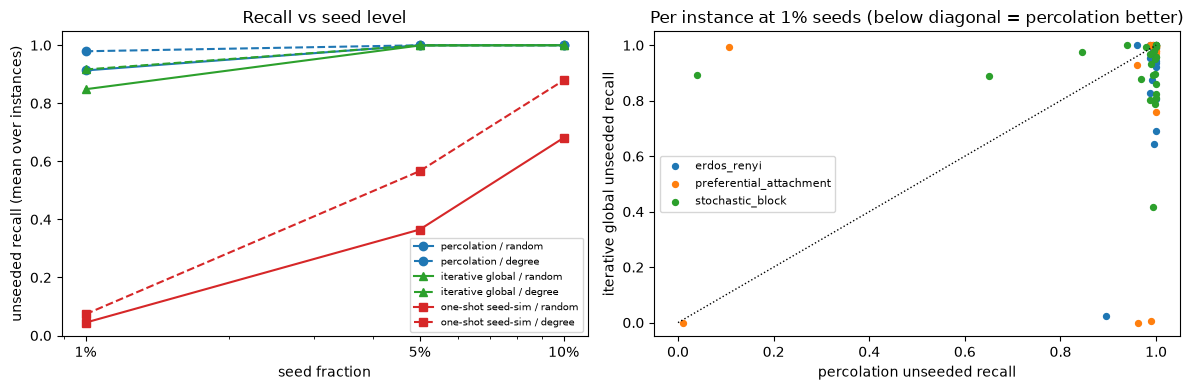

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (col, lab, c, mk) in (("perc", "percolation", "C0", "o"), ("iter", "iterative global", "C2", "^"), ("sim", "one-shot seed-sim", "C3", "s")):
    for kind, ls in (("random", "-"), ("degree", "--")):
        g = cmp[cmp.seed_kind == kind].groupby("seed_pct")[f"unseeded_recall_{col}"].mean()
        ax[0].plot(g.index, g.values, ls, marker=mk, c=c, label=f"{lab} / {kind}")
ax[0].set_xscale("log"); ax[0].set_xticks([1, 5, 10]); ax[0].set_xticklabels(["1%", "5%", "10%"])
ax[0].set_xlabel("seed fraction"); ax[0].set_ylabel("unseeded recall (mean over instances)"); ax[0].legend(fontsize=7); ax[0].set_title("Recall vs seed level")
for fam, g in cmp[cmp.seed_pct == 1].groupby("family"):
    ax[1].scatter(g.unseeded_recall_perc, g.unseeded_recall_iter, label=fam, s=18)
ax[1].plot([0, 1], [0, 1], "k:", lw=1); ax[1].set_xlabel("percolation unseeded recall"); ax[1].set_ylabel("iterative global unseeded recall")
ax[1].set_title("Per instance at 1% seeds (below diagonal = percolation better)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "figs" / "comparison.png", dpi=130); plt.show()

## 6. What happens across rounds
On Val with the frozen config: how many nodes get locked in each round and how accurate those locked pairs are (diagnostic; pairs pooled within the Val instances).

In [11]:
rows = []
for pct in (1, 5):
    for name in list_instances("val"):
        A_, B_, s_, tr_, mt_ = load_instance("val", name, "random", pct)
        _, inf_ = match_iter(A_, B_, s_, **cfg3)
        inf_["correct"] = [tr_[a] == b for a, b in zip(inf_.node_a, inf_.node_b)]
        inf_["pct"] = pct; inf_["instance"] = name
        rows.append(inf_)
rd = pd.concat(rows, ignore_index=True)
rd["round_bin"] = pd.cut(rd["round"], [0, 1, 2, 3, 5, 10, 20, 400])
tbl = rd.groupby(["pct", "round_bin"], observed=True).agg(pairs_locked=("correct", "size"), precision=("correct", "mean"), mean_votes=("score", "mean")).round(3)
display(tbl)
display(Markdown("**Rounds used per instance (frozen config, Val, random seeds)**"))
display(rd.groupby(["pct", "instance"])["round"].max().groupby("pct").describe().round(1))

pairs_locked  precision  mean_votes
pct round_bin                                     
1   (0, 1]               52      0.538       2.346
    (1, 2]              187      0.369       2.861
    (2, 3]              294      0.548       4.041
    (3, 5]              856      0.821       6.907
    (5, 10]            2380      0.958      10.189
    (10, 20]           1528      0.957      11.281
    (20, 400]           296      0.365       6.166
5   (0, 1]              392      0.997       4.296
    (1, 2]              643      0.998       7.986
    (2, 3]              692      1.000      11.408
    (3, 5]             1250      1.000      13.568
    (5, 10]            1636      1.000      15.012
    (10, 20]            727      1.000      15.831
    (20, 400]            71      0.972      13.155

**Rounds used per instance (frozen config, Val, random seeds)**

,count,mean,std,min,25%,50%,75%,max
pct,,,,,,,,
1,9.0,32.9,6.2,26.0,29.0,30.0,34.0,43.0
5,9.0,25.8,2.4,23.0,24.0,25.0,27.0,30.0


## Takeaways (iterative global vs percolation vs one-shot)

**Iterating is what matters, not greedy-vs-global.** Mean unseeded recall over Train+Val:

| seeds | percolation | iterative global | one-shot (solution 2) |
|---|---|---|---|
| 1% random | 0.913 | 0.848 | 0.044 |
| 1% degree | 0.979 | 0.916 | 0.073 |
| 5% random | 1.000 | 0.999 | 0.365 |
| 5% degree | 1.000 | 1.000 | 0.566 |
| 10% | 1.000 | 1.000 | 0.68 / 0.88 |

At 5% and 10% seeds the iterative global method is essentially tied with percolation (equal within 0.005 recall on 96% of instances at 5%, 100% at 10%). Both are far above one-shot, so most of the gain comes from turning matches into new anchors.

**At 1% seeds percolation is better:** it wins on 67% of instances, iterative global on 15% (18% tie). Preferential-attachment graphs show the largest gap (0.75 vs 0.84 recall, random seeds). The first rounds at 1% lock in few and unreliable pairs (precision 0.37 to 0.55 for rounds 1 to 3, with only 2 to 3 votes each), and early errors then feed later rounds; percolation's per-pair greedy ordering with `r=1` recovers better from the same weak start.

**Tuning.** The winner locks in only the best 20% of confident pairs per round (`frac=0.2`), needs at least 2 votes (`tau=2`), no margin; locking everything at once (`frac=1.0`) collapsed to one-shot-like behaviour (Val unseeded F1 0.22 to 0.74 vs 0.88 to 1.0). Margin rules and the final `finish` step hurt or did nothing, as with percolation. The best `frac` sits at the edge of my grid (0.2 vs 1.0), and locking in fewer pairs per round approaches percolation's one-at-a-time greedy matching, so I'd expect smaller `frac` to close part of the 1% gap; I did not test that.

**Runtime.** About 0.23 s at n=1000, roughly 2.5x faster than my percolation implementation (0.57 s), because each round is vectorised, though it needs about 25 to 30 rounds.

**Conclusion.** Percolation stays the main method: it is as accurate at 5%+ and clearly better at 1%. Iterative global assignment is a credible, slightly faster alternative that confirms the key ingredient is iterative anchor growth with conservative lock-in.